# Exercise: Can an encoder find malaria?

Each image is one blood cell. Some cells are **parasitized** (infected with malaria). Some are **uninfected**.

We used a pretrained encoder (DINOv2) to turn each image into a row of 768 numbers.

## Setup

In [19]:
library('tidymodels')
library('embed')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

## 1. Load the data

Here are 6 example cells. The top row is parasitized. The bottom row is uninfected.

<img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/parasitized_C129P90ThinF_IMG_20151004_133921_cell_105.png" width="90"><img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/parasitized_C189P150ThinF_IMG_20151203_140809_cell_133.png" width="90"> <img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/parasitized_C52P13thinF_IMG_20150725_130013_cell_194.png" width="90"> <br><img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/uninfected_C147P108ThinF_IMG_20151115_101156_cell_82.png" width="90"> <img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/uninfected_C184P145ThinF_IMG_20151203_102405_cell_137.png" width="90"> <img src="https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_examples/uninfected_C77P38ThinF_IMG_20150601_152941_cell_55.png" width="90">

The encoder already ran. Each row of `malaria` is one image. `e1` to `e768` are its embedding.

In [20]:
malaria <- readr::read_csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_embeddings.csv.gz', show_col_types = FALSE) |>
    mutate(label = factor(label, levels = c('uninfected', 'parasitized')))

malaria |> select(id, label, e1:e5) |> head()

 [100%] Downloaded 3010429 bytes...
                                                                              

  id                                         label      e1     e2      e3    
1 C184P145ThinF_IMG_20151203_102405_cell_137 uninfected 0.0045  0.0178 0.0393
2 C77P38ThinF_IMG_20150601_152941_cell_55    uninfected 0.0321 -0.0049 0.0702
3 C147P108ThinF_IMG_20151115_101156_cell_82  uninfected 0.0174 -0.0118 0.0692
4 C223ThinF_IMG_20151112_104410_cell_156     uninfected 0.0114 -0.0091 0.0375
5 C92P53ThinF_IMG_20150821_151646_cell_32    uninfected 0.0226  0.0284 0.0138
6 C83P44ThinF_IMG_20150817_134331_cell_194   uninfected 0.0194 -0.0292 0.0345
  e4      e5     
1 -0.0475  0.0563
2 -0.0556 -0.0220
3 -0.0476 -0.0041
4 -0.0590  0.0046
5 -0.0545  0.0345
6 -0.0767  0.0011

In [21]:
malaria |> count(label)

  label       n   
1 uninfected  1000
2 parasitized 1000

## 2. Visualize with UMAP

We cannot plot 768 dimensions at once. **UMAP** squeezes all the dimensions into 2 new columns, `UMAP1` and `UMAP2`. Similar images wil have similar `UMAP1` and `UMAP2` values.

Run the cell. It makes the 2 UMAP columns. (It takes a few seconds.)

In [22]:
set.seed(1)

umap_coords <- recipe(label ~ ., data = select(malaria, -id)) |>
    step_umap(all_predictors(), num_comp = 2) |>
    prep() |>
    bake(new_data = NULL)

umap_coords |> head()

  label      UMAP1     UMAP2     
1 uninfected -3.885077 -0.1045645
2 uninfected -2.033472  1.3991832
3 uninfected -2.757028 -0.8090479
4 uninfected -4.483551 -0.1679591
5 uninfected -2.477914  4.1084366
6 uninfected -2.114880  2.5737996

**Your turn:** plot `UMAP1` against `UMAP2`. Color the points by `label`.

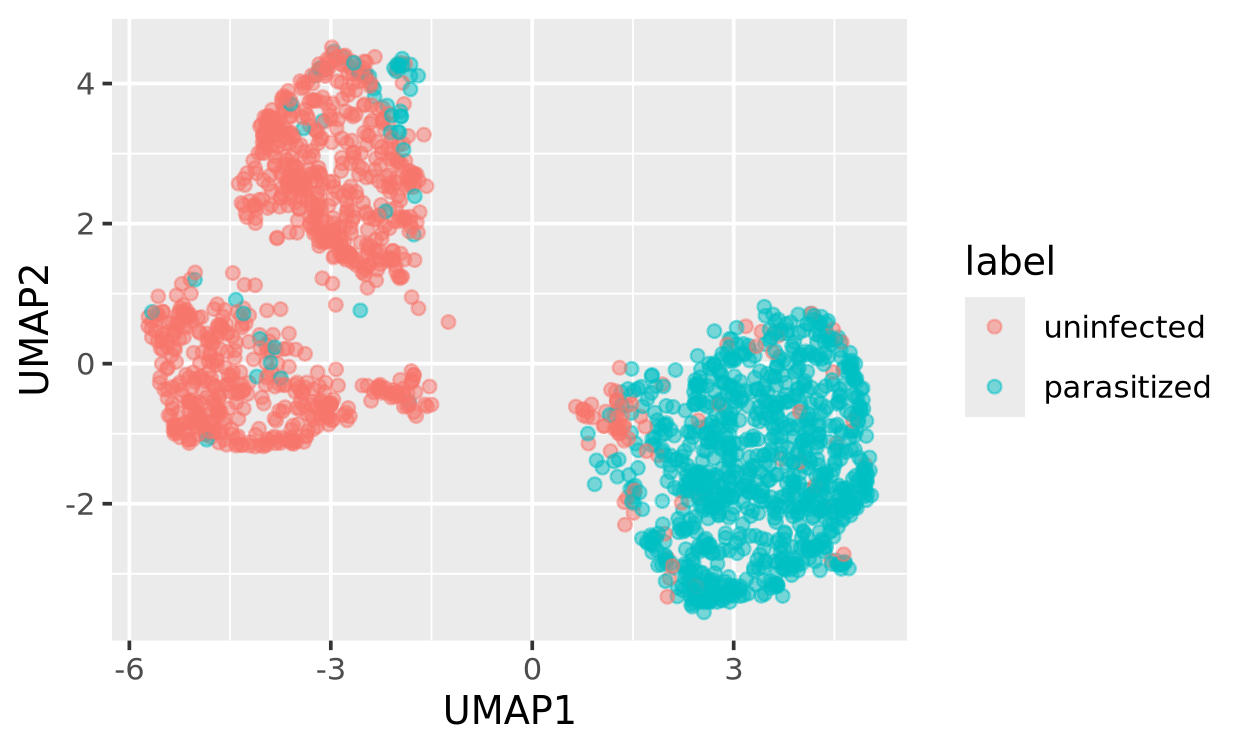

In [23]:
# Chart code goes here

ggplot(umap_coords, aes(x = UMAP1, y = UMAP2, color = label)) +
    geom_point(alpha = 0.5)

**Check:** do the two kinds of cell land in different places?

- Do you see clear groups? Are they perfectly separate?
- Which cells are hard to tell apart?

**Answer:** Yes. The two classes form two mostly distinct clusters, so the encoder places parasitized and uninfected cells in different regions. The groups are **not** perfectly separate: there is a band where the two colors overlap. The hard-to-tell-apart cells are those in that overlapping region, where the two clouds blend.

## 3. Split the data

Run this cell. Do not change it.

- `train`: half of the images. The model learns from these.
- `test`: the other half. The model has never seen these. We measure accuracy here.

In [24]:
set.seed(512)

split <- initial_split(malaria, prop = 0.5, strata = label)
train <- training(split) |> select(-id)
test  <- testing(split)  |> select(-id)

nrow(train)

[1] 1000

## 4. Pick a model

Pick a classifier model that we've worked with before (e.g. random forest). Fit it on `train`. Find the accuracy on `test`.

Options:

- `logistic_reg(penalty = 0.01, mixture = 0) |> set_engine('glmnet')`: logistic regression. We have 768 columns, so it needs a `penalty` (like in lecture 16).
- `rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger')`: random forest.
- `mlp(hidden_units = 10, epochs = 500) |> set_mode('classification') |> set_engine('nnet', MaxNWts = 10000)`: neural net.

Use the formula `label ~ .` (all other embeddings columns are predictors).

In [25]:
# Fit your model here

set.seed(1)

fit <- rand_forest(trees = 200) |>
    set_mode('classification') |>
    set_engine('ranger') |>
    fit(label ~ ., data = train)

fit

parsnip model object

Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, num.trees = 200,      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  200 
Sample size:                      1000 
Number of independent variables:  768 
Mtry:                             27 
Target node size:                 10 
Variable importance mode:         none 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.04196547 

<details>
<summary>Hint: how do I find the accuracy?</summary>

1. `predict()` gives the predicted class for each test image.
2. `bind_cols()` puts it next to the true `label`.
3. `accuracy()` compares them.

```r
predict(fit, new_data = test) |>
    bind_cols(test) |>
    accuracy(truth = label, estimate = .pred_class)
```

Here `fit` is the name of your fitted model. Use your own name.

</details>

In [28]:
# Accuracy on the test set
print(predict(fit, new_data = train) |>
    bind_cols(train) |>
    accuracy(truth = label, estimate = .pred_class))

predict(fit, new_data = test) |>
    bind_cols(test) |>
    accuracy(truth = label, estimate = .pred_class)

# A tibble: 1 × 3
  .metric  .estimator .estimate
  <chr>    <chr>          <dbl>
1 accuracy binary         0.998


  .metric  .estimator .estimate
1 accuracy binary     0.939    

**Check:** a good model gets about 0.93 to 0.95 on the test images.

- Why did you pick this model?
- Is the accuracy on `train` higher than on `test`? What does that tell you?

**Answer:** I used a random forest because it works well off-the-shelf with many (768) correlated predictors, needs no scaling or tuning, and is robust to the redundant embedding columns.

The accuracy on `train` (0.998) is **higher** than on `test` (0.939). That gap is mild overfitting: the forest fits the training images (including their noise) almost perfectly, so it looks better there than on the unseen test images. The test accuracy is still in the expected 0.93–0.95 range, so the embeddings generalize well.

## 5. Bonus: raw pixels

We also have the raw pixels for the same cells: `malaria_pixels.csv.gz`. That is 32 x 32 = 1,024 columns named `p1` to `p1024`.

Use the same split. Fit the same kind of model on the pixels. How does the test accuracy compare to the embeddings?

In [27]:
pixels <- readr::read_csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/malaria_pixels.csv.gz', show_col_types = FALSE) |>
    mutate(label = factor(label, levels = c('uninfected', 'parasitized')))

# Use the same split: train_pix has the same images as train
train_pix <- pixels |> filter(id %in% training(split)$id) |> select(-id)
test_pix  <- pixels |> filter(id %in% testing(split)$id)  |> select(-id)

# Fit and evaluate here

set.seed(1)

fit_pix <- rand_forest(trees = 200) |>
    set_mode('classification') |>
    set_engine('ranger') |>
    fit(label ~ ., data = train_pix)

predict(fit_pix, new_data = test_pix) |>
    bind_cols(test_pix) |>
    accuracy(truth = label, estimate = .pred_class)

 [100%] Downloaded 1556446 bytes...
                                                                              

  .metric  .estimator .estimate
1 accuracy binary     0.719    

*Your answer:* Which is better for finding malaria: pixels or embeddings? Why?

**Answer:** Embeddings are much better. The same random forest gets ~0.94 on the 768 embedding columns but only ~0.72 on the 1,024 raw pixels. Raw pixels are low-level, high-dimensional, and vary with lighting/position, so the model has to learn the biology from scratch and overfits. DINOv2's embeddings are learned, compressed visual features that already encode the meaningful cell structure, so they separate parasitized from uninfected cells far more cleanly.